In [149]:
import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.primitives import StatevectorEstimator
from qiskit.circuit.library import z_feature_map, efficient_su2
from qiskit_machine_learning.circuit.library import qnn_circuit
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.algorithms.regressors import NeuralNetworkRegressor
from IPython.display import clear_output

In [30]:
data_orig = np.load("data.npy", allow_pickle=True)

In [31]:
data_orig = data_orig[96:]

In [32]:
n = 240

In [33]:
data = ((2*np.pi) * (data_orig - min(data_orig[0:(8+n)])) / (max(data_orig[0:(8+n)]) - min(data_orig[0:(8+n)]))) - np.pi

In [34]:
inputs = []
for i in range(n):
    inputs.append(data[i:(i+8)])
inputs = np.array(inputs)

In [35]:
outputs = np.array(data[8:(8+n)])

In [36]:
outputs = ((outputs - min(outputs)) / (max(outputs) - min(outputs))) - 0.5

In [175]:
x = ParameterVector("in", 8)
θ = ParameterVector("θ", 80)

In [188]:
fm = z_feature_map(8, reps=1)

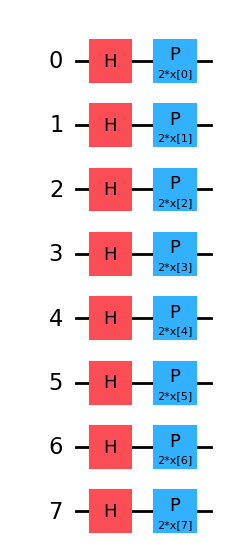

In [189]:
fm.draw(output="mpl", fold=-1)

In [178]:
pqc = efficient_su2(8, reps=4)

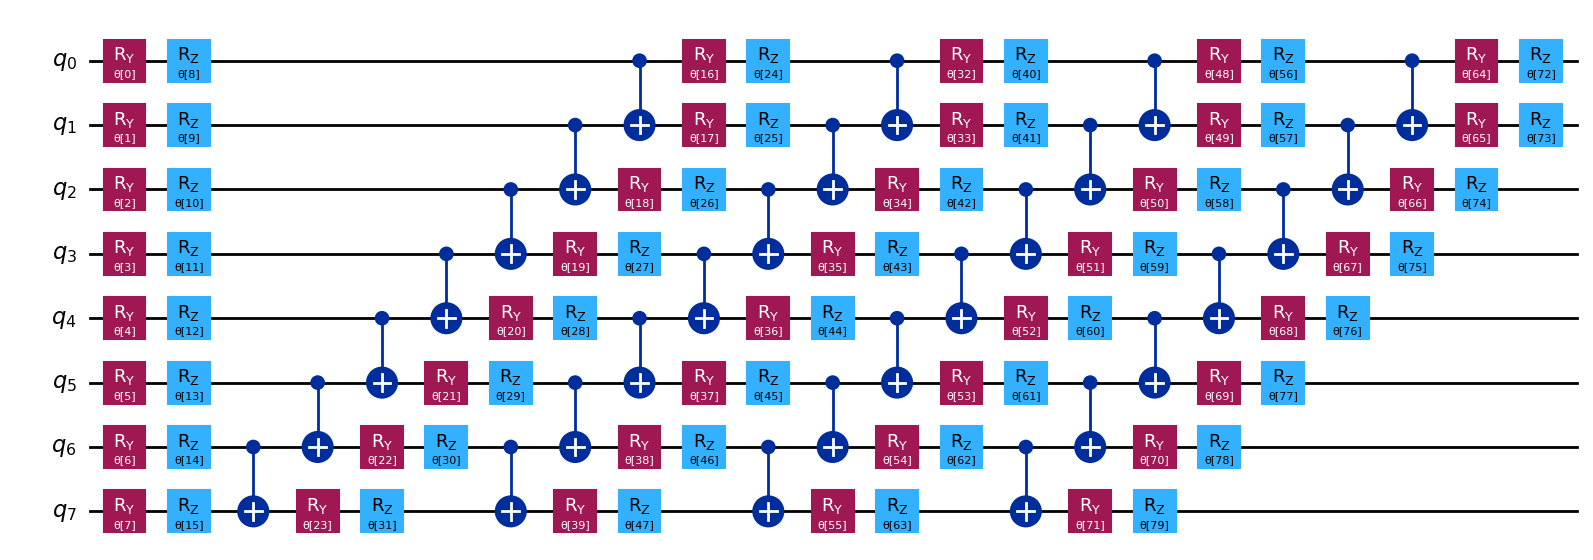

In [179]:
pqc.draw(output="mpl", fold=-1)

In [190]:
# construct a circuit
qc, fm_params, pqc_params = qnn_circuit(feature_map=fm, ansatz=pqc)

In [191]:
estimator = StatevectorEstimator(seed=42)

In [192]:
# construct QNN
regression_estimator_qnn = EstimatorQNN(
    circuit=qc, input_params=fm_params, weight_params=pqc_params, estimator=estimator
)

No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


In [193]:
# callback function that draws a live plot when the .fit() method is called
def callback_graph(weights, obj_func_eval):
    clear_output(wait=True)
    objective_func_vals.append(obj_func_eval)
    plt.title("Objective function value against iteration")
    plt.xlabel("Iteration")
    plt.ylabel("Objective function value")
    plt.plot(range(len(objective_func_vals)), objective_func_vals)
    plt.show()

In [198]:
# construct the regressor from the neural network
regressor = NeuralNetworkRegressor(
    neural_network=regression_estimator_qnn,
    loss="absolute_error",
    optimizer=COBYLA(maxiter=5000),
    initial_point = ((2*np.pi)*np.random.random(len(pqc_params)))-np.pi,
    callback=callback_graph,
)

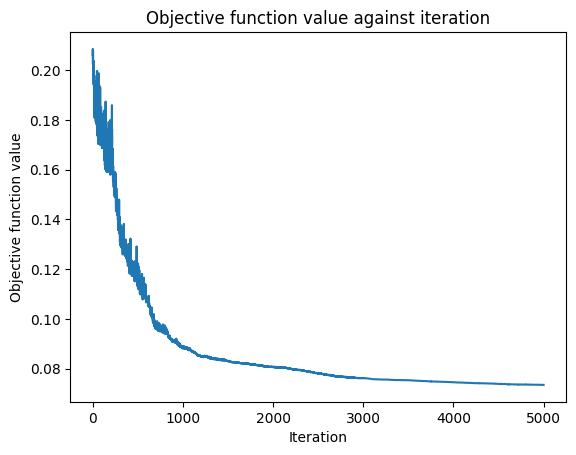

In [199]:
# fit to data
objective_func_vals = []
regressor.fit(inputs, outputs)

In [200]:
score = regressor.score(inputs, outputs)

In [202]:
print(score)
#regressor.to_dill(f"QNN_{score}-model_state.dill")

0.7706084854606758


In [207]:
[1,2,3] - [4,5,6]

TypeError: unsupported operand type(s) for -: 'list' and 'list'

In [206]:
np.array(1, 2, 3) - np.array(1, 2, 3)

TypeError: array() takes from 1 to 2 positional arguments but 3 were given